# 03 — Model Training

## Import Libraries

In [12]:

# Import libraries for working with data
from pathlib import Path
import numpy as np
import pandas as pd

# Import tools for splitting and evaluating models
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Import our five classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Import our reusable preprocessing functions
import sys

project_dir = Path.cwd()

if not (project_dir / "ml" / "preprocessing.py").exists():
    project_dir = project_dir.parent

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from ml.preprocessing import load_dataset, create_model_pipeline

import warnings

# Hide the known SVM probability deprecation warning
warnings.filterwarnings(
    "ignore",
    message=r".*`probability` parameter.*",
    category=FutureWarning,
    module=r"sklearn\.svm\._base"
)


## Load Dataset

In [13]:

# Load the original diabetes dataset
df = load_dataset()

# Separate the input features and target labels
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# Display the dataset dimensions
print("Dataset shape:", df.shape)
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Dataset shape: (768, 9)
Features shape: (768, 8)
Target shape: (768,)


## Train/Test Split

In [14]:

# Create the same stratified split used in Phase 2
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the training and testing sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (614, 8)
Testing features: (154, 8)
Training labels: (614,)
Testing labels: (154,)


## Initialize Machine Learning Models

In [15]:

# Initialize five classification models with reproducible settings
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}

# Display the models we will train
for name in models:
    print(name)


Logistic Regression
Decision Tree
Random Forest
Support Vector Machine
K-Nearest Neighbors


## Train Baseline Models

In [16]:

# Store the trained model pipelines
trained_models = {}

# Train each model with its own preprocessing pipeline
for name, model in models.items():

    # Tree-based models do not need feature scaling
    needs_scaling = name not in ["Decision Tree", "Random Forest"]

    # Combine preprocessing and classification
    pipeline = create_model_pipeline(
        model=model,
        scale=needs_scaling
    )

    # Fit preprocessing and model using training data only
    pipeline.fit(X_train, y_train)

    # Save the fitted pipeline for later evaluation
    trained_models[name] = pipeline

    print(f"{name}: Training completed")

# Confirm all five models were trained
print(f"\nTotal trained models: {len(trained_models)}")


Logistic Regression: Training completed
Decision Tree: Training completed
Random Forest: Training completed
Support Vector Machine: Training completed
K-Nearest Neighbors: Training completed

Total trained models: 5


## Stratified Cross-Validation

In [17]:

# Create five stratified folds with reproducible shuffling
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Cross-validation configured successfully.")


Cross-validation configured successfully.


## Cross-Validation Results

In [18]:

# Store cross-validation results for each model
cv_results = []

# Evaluate every model using the training dataset
for name, model in models.items():

    # Enable scaling for models that benefit from it
    needs_scaling = name not in ["Decision Tree", "Random Forest"]

    # Create a fresh preprocessing and model pipeline
    pipeline = create_model_pipeline(
        model=model,
        scale=needs_scaling
    )

    # Refit preprocessing and the model separately within each fold
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    # Calculate the average score for each metric
    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

    print(f"{name}: Cross-validation completed")

# Convert results into a comparison table
cv_results_df = pd.DataFrame(cv_results)

# Sort models by average F1-score
cv_results_df = cv_results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(cv_results_df.round(4))


Logistic Regression: Cross-validation completed
Decision Tree: Cross-validation completed
Random Forest: Cross-validation completed
Support Vector Machine: Cross-validation completed
K-Nearest Neighbors: Cross-validation completed


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,F1 Std
0,Logistic Regression,0.7882,0.7638,0.5748,0.6545,0.8434,0.0244
1,Support Vector Machine,0.7801,0.7415,0.5842,0.6485,0.8333,0.0187
2,Random Forest,0.7606,0.6899,0.5750,0.6258,0.8163,0.0274
3,K-Nearest Neighbors,0.7296,0.6367,0.5654,0.5939,0.7843,0.0469
4,Decision Tree,0.6726,0.5306,0.5795,0.5519,0.6510,0.0268


## Hyperparameter Tuning

In [19]:

# Import the tool for searching model hyperparameters
from sklearn.model_selection import GridSearchCV


## Define Hyperparameter Grids

In [20]:

# Define candidate settings for our three strongest models
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    "Support Vector Machine": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"],
        "model__class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5, 10, None],
        "model__min_samples_split": [2, 5],
        "model__min_samples_leaf": [1, 2],
        "model__class_weight": [None, "balanced"]
    }
}

# Display the number of parameter combinations for each model
for name, grid in param_grids.items():
    combinations = np.prod([len(values) for values in grid.values()])
    print(f"{name}: {combinations} combinations")


Logistic Regression: 10 combinations
Support Vector Machine: 24 combinations
Random Forest: 64 combinations


## Tune Machine Learning Models

In [21]:

# Store the best fitted pipelines and their tuning results
tuned_models = {}
tuning_results = []

# Tune the three strongest baseline models
for name in param_grids:

    print(f"\nTuning {name}...")

    # Apply scaling only where appropriate
    needs_scaling = name != "Random Forest"

    # Create a fresh model pipeline
    pipeline = create_model_pipeline(
        model=models[name],
        scale=needs_scaling
    )

    # Search for the best settings using training folds only
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    # Fit all candidate configurations on the training data
    grid_search.fit(X_train, y_train)

    # Save the best fitted pipeline
    tuned_models[name] = grid_search.best_estimator_

    # Record the best cross-validation result
    tuning_results.append({
        "Model": name,
        "Best F1-Score": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

    print(f"Best F1-Score: {grid_search.best_score_:.4f}")
    print(f"Best Parameters: {grid_search.best_params_}")

# Display a summary of the tuning results
tuning_results_df = pd.DataFrame(tuning_results)
display(tuning_results_df)



Tuning Logistic Regression...
Best F1-Score: 0.6823
Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}

Tuning Support Vector Machine...
Best F1-Score: 0.6902
Best Parameters: {'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Tuning Random Forest...
Best F1-Score: 0.6980
Best Parameters: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 100}


,Model,Best F1-Score,Best Parameters
0,Logistic Regression,0.682340,"{'model__C': 0.1, 'model__class_weight': 'bala..."
1,Support Vector Machine,0.690163,"{'model__C': 1, 'model__class_weight': 'balanc..."
2,Random Forest,0.698022,"{'model__class_weight': 'balanced', 'model__ma..."


## Baseline vs Tuned Models

In [22]:

# Compare original cross-validation scores against tuned scores
comparison_results = []

for result in tuning_results:
    name = result["Model"]

    # Retrieve the original baseline F1-score
    baseline_f1 = cv_results_df.loc[
        cv_results_df["Model"] == name,
        "F1-Score"
    ].iloc[0]

    tuned_f1 = result["Best F1-Score"]

    comparison_results.append({
        "Model": name,
        "Baseline F1": baseline_f1,
        "Tuned F1": tuned_f1,
        "Difference": tuned_f1 - baseline_f1
    })

# Display the comparison table
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(4))


,Model,Baseline F1,Tuned F1,Difference
0,Logistic Regression,0.6545,0.6823,0.0278
1,Support Vector Machine,0.6485,0.6902,0.0417
2,Random Forest,0.6258,0.6980,0.0722


## Classification Threshold Analysis

In [24]:

# Import tools for validation predictions and classification metrics
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

# Store threshold results for all three tuned models
threshold_results = []

# Evaluate different thresholds for each tuned model
for name, model in tuned_models.items():

    # Generate out-of-fold probabilities using training data only
    cv_probabilities = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Test several classification thresholds
    for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

        # Convert probabilities into binary predictions
        predictions = (cv_probabilities >= threshold).astype(int)

        # Calculate classification performance
        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_train, predictions, zero_division=0),
            "Recall": recall_score(y_train, predictions, zero_division=0),
            "F1-Score": f1_score(y_train, predictions, zero_division=0)
        })

    print(f"{name}: Threshold analysis completed")

# Display the complete comparison table
threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))


Logistic Regression: Threshold analysis completed
Support Vector Machine: Threshold analysis completed
Random Forest: Threshold analysis completed


,Model,Threshold,Precision,Recall,F1-Score
0,Logistic Regression,0.30,0.5000,0.9112,0.6457
1,Logistic Regression,0.35,0.5431,0.8832,0.6726
2,Logistic Regression,0.40,0.5641,0.8224,0.6692
3,Logistic Regression,0.45,0.5986,0.7944,0.6827
4,Logistic Regression,0.50,0.6498,0.7196,0.6829
5,Logistic Regression,0.55,0.6810,0.6682,0.6745
6,Logistic Regression,0.60,0.7243,0.6262,0.6717
7,Support Vector Machine,0.30,0.6090,0.8224,0.6998
8,Support Vector Machine,0.35,0.6245,0.7850,0.6957
9,Support Vector Machine,0.40,0.6390,0.7196,0.6769


## Final Model Evaluation

In [25]:

# Import evaluation metrics for the final test
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Lock our selected model and classification threshold
final_model_name = "Random Forest"
final_threshold = 0.40
final_model = tuned_models[final_model_name]

# Generate probabilities for the untouched test records
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Convert probabilities into predictions using our selected threshold
test_predictions = (test_probabilities >= final_threshold).astype(int)

# Calculate final evaluation metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities)
}

# Display the final test results
print(f"Model: {final_model_name}")
print(f"Threshold: {final_threshold}")

for metric, score in final_metrics.items():
    print(f"{metric}: {score:.4f}")

# Display the detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, test_predictions, zero_division=0))

# Display the confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, test_predictions))


Model: Random Forest
Threshold: 0.4
Accuracy: 0.7273
Precision: 0.5732
Recall: 0.8704
F1-Score: 0.6912
ROC-AUC: 0.8220

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.65      0.76       100
           1       0.57      0.87      0.69        54

    accuracy                           0.73       154
   macro avg       0.74      0.76      0.72       154
weighted avg       0.79      0.73      0.73       154

Confusion Matrix:
[[65 35]
 [ 7 47]]


## Confusion Matrix Visualization

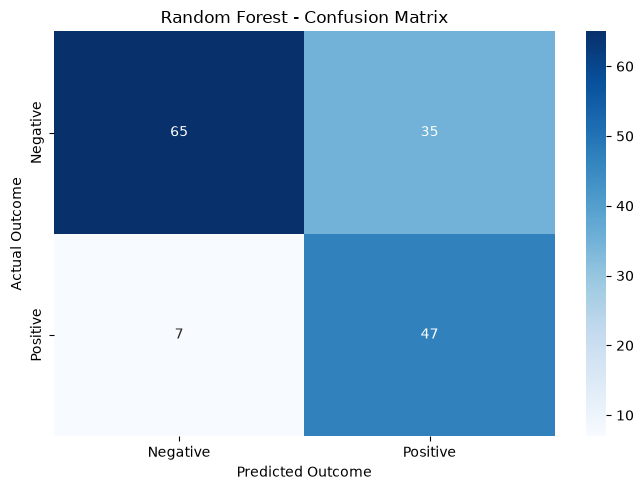

In [26]:

# Import libraries for plotting evaluation results
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the confusion matrix using final test predictions
cm = confusion_matrix(y_test, test_predictions)

# Create a heatmap showing correct and incorrect predictions
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

# Add descriptive labels and title
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.show()


## ROC Curve Visualization

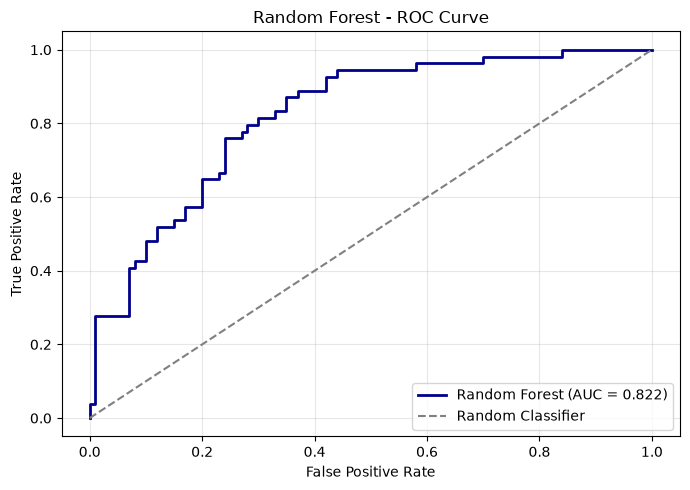

In [27]:

# Import tools for calculating ROC curve coordinates
from sklearn.metrics import roc_curve, auc

# Calculate false positive and true positive rates
fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

# Calculate the area under the ROC curve
roc_auc = auc(fpr, tpr)

# Plot the ROC curve for our selected model
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    color="darkblue",
    linewidth=2,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

# Add the random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

# Add chart labels and formatting
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Permutation Feature Importance

In [28]:

# Import tools for permutation importance and cross-validation
from sklearn.inspection import permutation_importance
from sklearn.base import clone

# Store feature importance scores from validation folds
importance_results = []

# Evaluate feature importance across five training folds
for fold_number, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):

    # Create separate training and validation subsets
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # Train a fresh copy of our selected Random Forest pipeline
    fold_model = clone(final_model)
    fold_model.fit(X_fold_train, y_fold_train)

    # Measure how shuffling each feature changes model performance
    result = permutation_importance(
        fold_model,
        X_fold_val,
        y_fold_val,
        scoring="roc_auc",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    # Store the average importance of each feature
    importance_results.append(result.importances_mean)

    print(f"Fold {fold_number}: Feature importance completed")

# Calculate average importance across validation folds
importance_array = np.array(importance_results)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance_array.mean(axis=0),
    "Std": importance_array.std(axis=0)
})

# Rank features from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))


Fold 1: Feature importance completed
Fold 2: Feature importance completed
Fold 3: Feature importance completed
Fold 4: Feature importance completed
Fold 5: Feature importance completed


,Feature,Importance,Std
0,Glucose,0.1306,0.0107
1,BMI,0.0445,0.0088
2,Age,0.0226,0.0040
3,Insulin,0.0178,0.0046
4,DiabetesPedigreeFunction,0.0077,0.0046
5,Pregnancies,0.0055,0.0038
6,SkinThickness,0.0012,0.0037
7,BloodPressure,-0.0011,0.0056


## Feature Importance Visualization

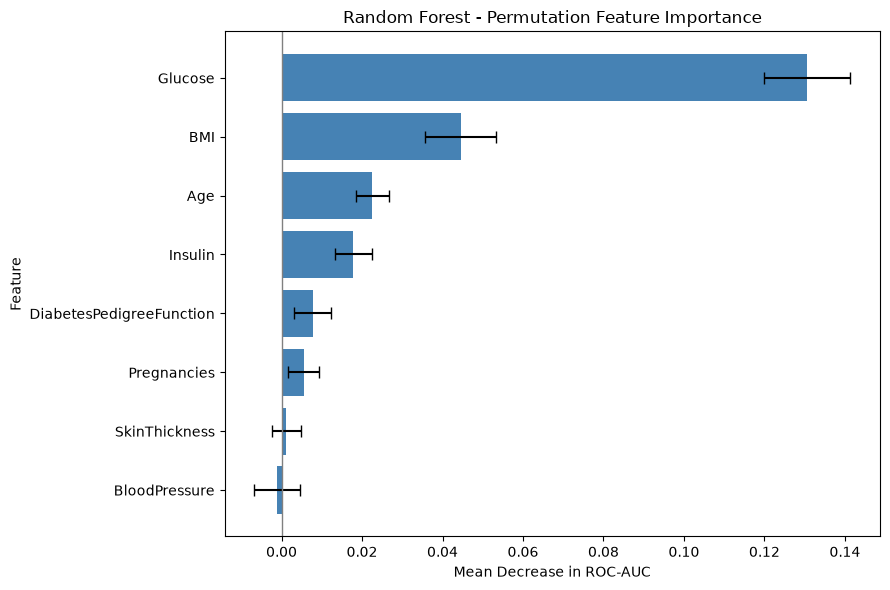

In [29]:

# Sort features for a horizontal importance chart
plot_df = importance_df.sort_values(
    by="Importance",
    ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(9, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"],
    color="steelblue",
    capsize=4
)

# Add labels and a reference line
plt.axvline(0, color="gray", linewidth=1)
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")
plt.title("Random Forest - Permutation Feature Importance")

plt.tight_layout()
plt.show()


## Save Final Model

In [30]:

# Import Joblib for saving the trained model
import joblib

# Create the models directory if it does not exist
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Save the fitted preprocessing and Random Forest pipeline
model_path = models_dir / "random_forest_pipeline.joblib"
joblib.dump(final_model, model_path)

# Save the classification threshold and feature names
config_path = models_dir / "model_config.joblib"

model_config = {
    "model_name": final_model_name,
    "threshold": final_threshold,
    "feature_names": X_train.columns.tolist(),
    "positive_class": 1
}

joblib.dump(model_config, config_path)

print("Model saved:", model_path)
print("Configuration saved:", config_path)


Model saved: /home/juthi/Documents/CSE306/UODA-DiaML/models/random_forest_pipeline.joblib
Configuration saved: /home/juthi/Documents/CSE306/UODA-DiaML/models/model_config.joblib


## Verify Saved Model

In [31]:

# Load the saved pipeline and its configuration
loaded_model = joblib.load(model_path)
loaded_config = joblib.load(config_path)

# Check that the loaded model produces the same probabilities
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Verify that saving and loading preserved the model
assert np.allclose(loaded_probabilities, test_probabilities)
assert loaded_config["threshold"] == final_threshold

print("Saved model verification passed.")
print("Model:", loaded_config["model_name"])
print("Threshold:", loaded_config["threshold"])
print("Features:", len(loaded_config["feature_names"]))


Saved model verification passed.
Model: Random Forest
Threshold: 0.4
Features: 8


In [32]:

# Display the exact settings of our selected Random Forest
rf_model = tuned_models["Random Forest"].named_steps["model"]

for parameter in [
    "n_estimators",
    "max_depth",
    "min_samples_split",
    "min_samples_leaf",
    "class_weight",
    "random_state"
]:
    print(f"{parameter}: {rf_model.get_params()[parameter]}")


n_estimators: 100
max_depth: 5
min_samples_split: 5
min_samples_leaf: 1
class_weight: balanced
random_state: 42
